In [113]:
%pip install cloudpickle

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

def load_housing_data():
    tarball_path = Path("../data/housing.tgz")
    if not tarball_path.is_file():
        Path("../data").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
    with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="../data")
    return pd.read_csv(Path("../data/housing/housing.csv"))

housing = load_housing_data()

C:\Users\DanieHKombe\AppData\Local\Temp\ipykernel_17700\3695951617.py:16: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  housing_tarball.extractall(path="../data")


In [2]:
target = "median_house_value"

In [3]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [5]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [6]:
print(housing[housing["total_bedrooms"].isnull()])

       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
182      -118.27     34.04                13.0       1784.0             NaN   
327      -117.65     34.04                15.0       3393.0             NaN   
366      -122.50     37.75                44.0       1819.0             NaN   
477      -117.99     34.14                30.0       2346.0             NaN   
495      -114.59     34.83                41.0        812.0             NaN   
...          ...       ...                 ...          ...             ...   
19880    -118.23     33.94                36.0       1110.0             NaN   
19952    -119.19     34.20                18.0       3620.0             NaN   
20088    -119.73     36.83                 8.0       3602.0             NaN   
20325    -118.88     34.17                15.0       4260.0             NaN   
20345    -122.22     38.15                 7.0       5129.0             NaN   

       population  households  median_income  media

In [7]:
print(f"Is null:\n {housing.isnull().sum()}")
print(f"\nUnique values:\n {housing.nunique()}")

Is null:
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Unique values:
 longitude               844
latitude                862
housing_median_age       52
total_rooms            5926
total_bedrooms         1923
population             3888
households             1815
median_income         12928
median_house_value     3842
ocean_proximity           5
dtype: int64


<Axes: >

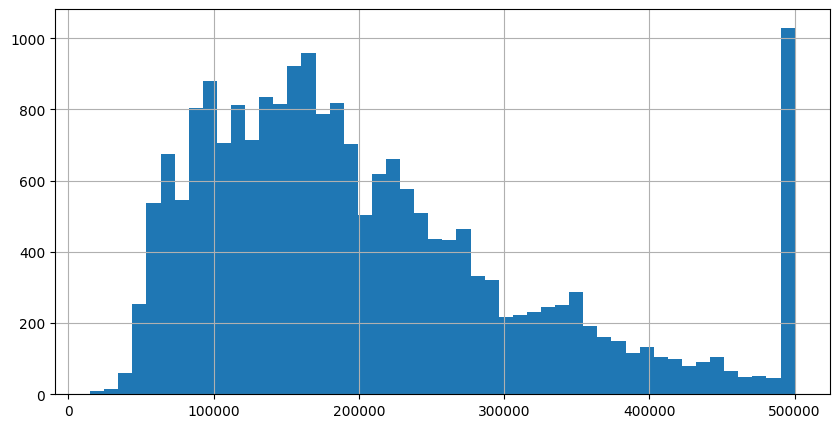

In [8]:
housing['median_house_value'].hist(bins=50, figsize=(10, 5))

In [9]:
# extra code – code to save the figures as high-res PNGs for the book

IMAGES_PATH = Path("../images") / "end_to_end_project"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

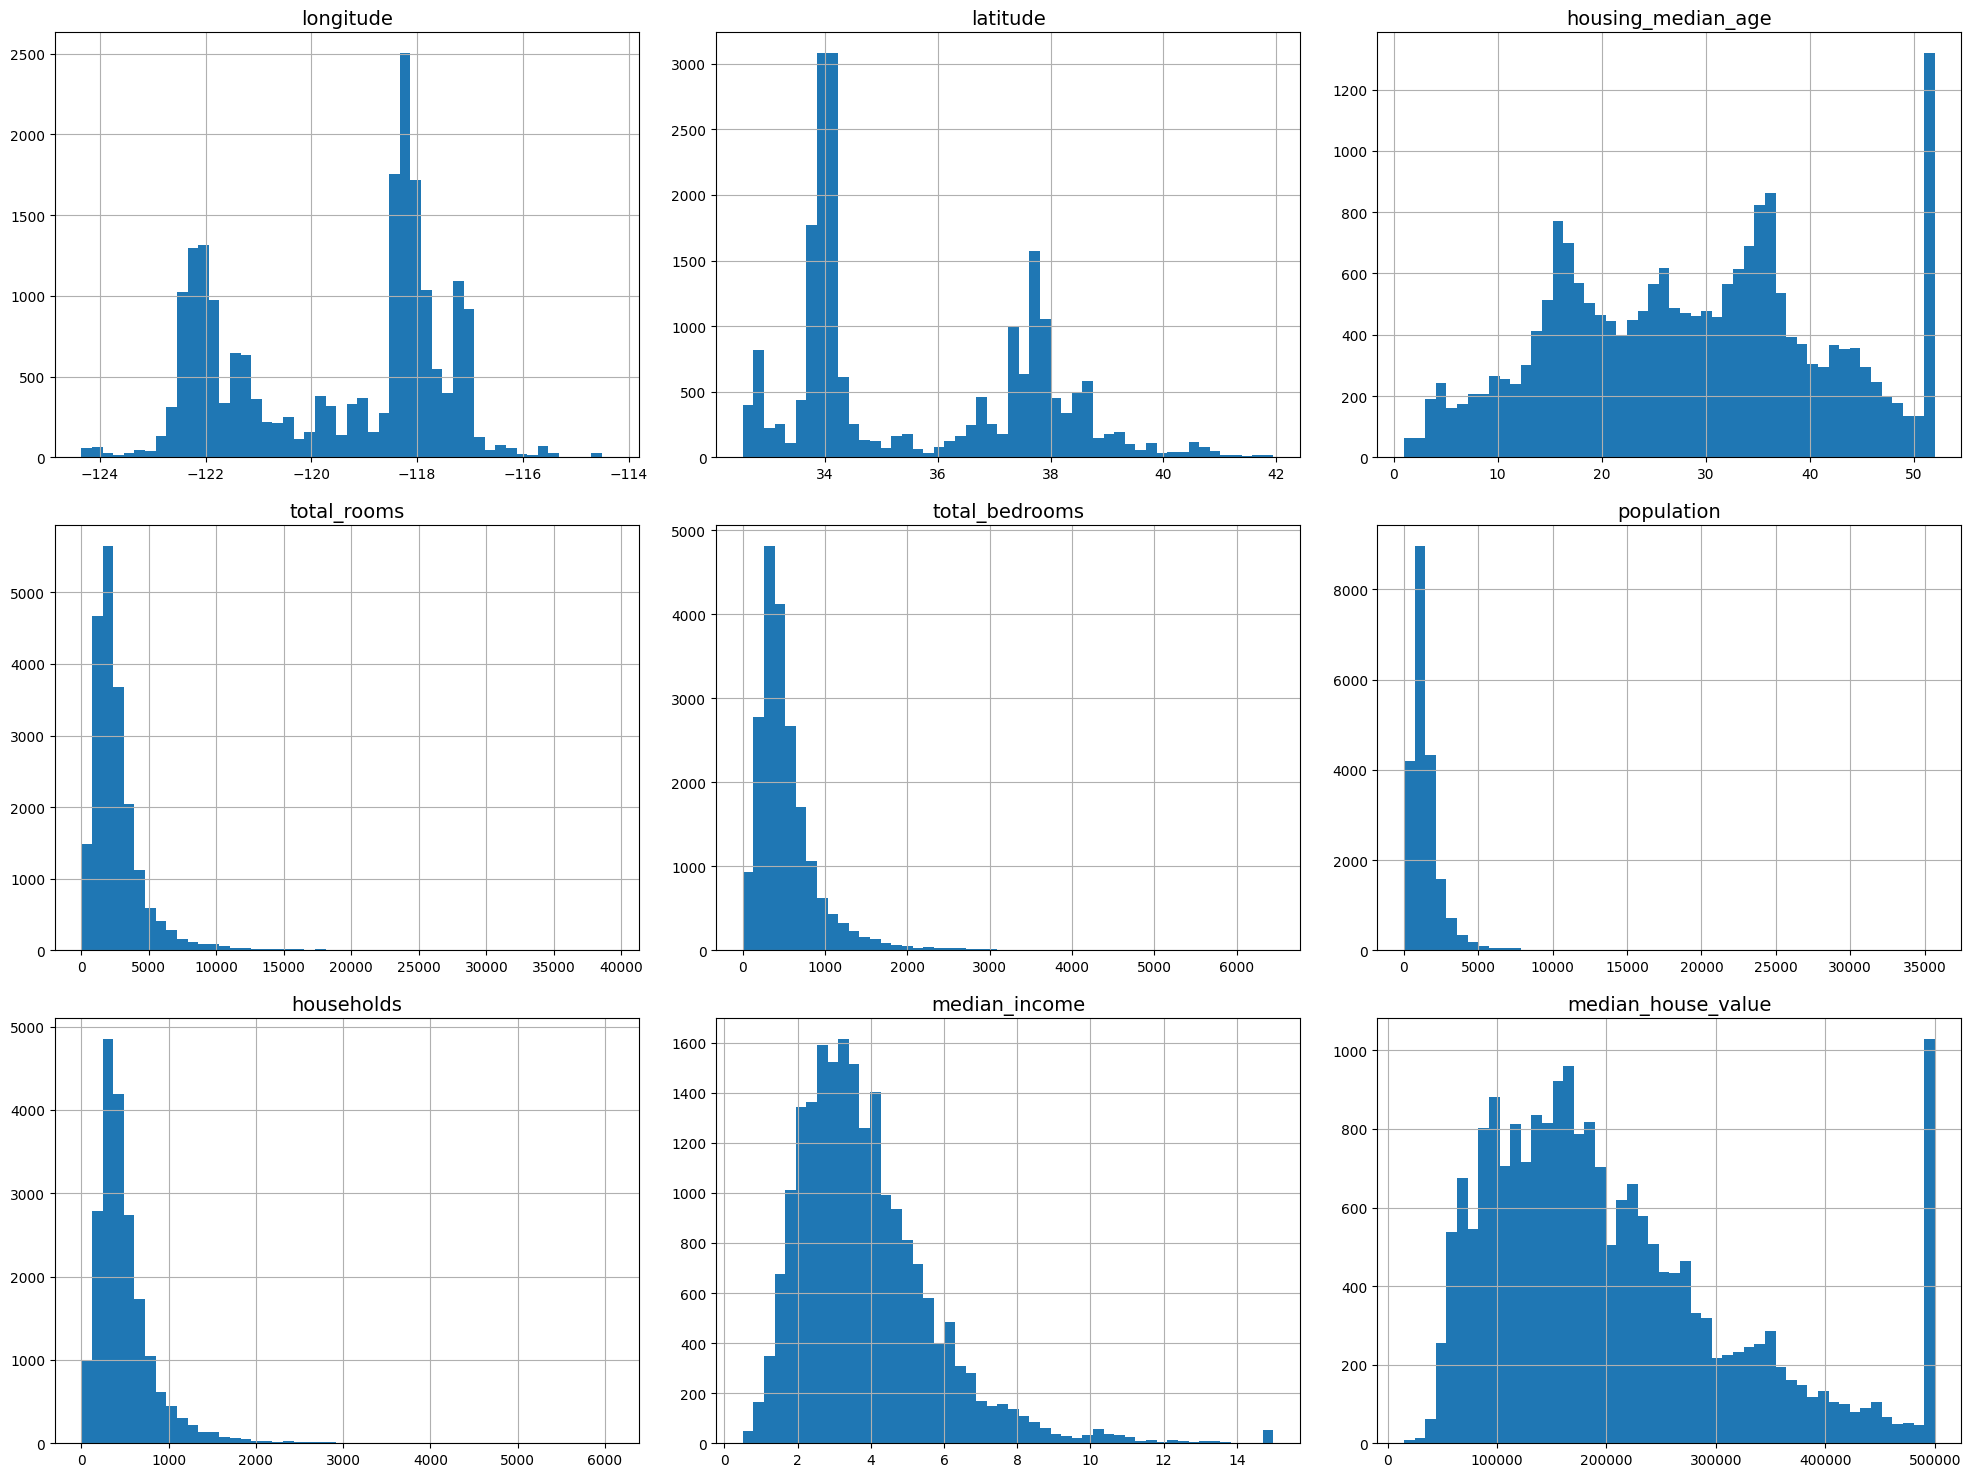

In [10]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

housing.hist(bins=50, figsize=(20, 15))
save_fig("attribute_histogram_plots")
plt.show()

In [11]:
def shuffle_and_split_data(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

In [12]:
train_set, test_set = shuffle_and_split_data(housing, 0.2)
len(train_set), len(test_set)

(16512, 4128)

In [13]:
from zlib import crc32

def is_id_in_test_set(identifier, test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_data_with_id_hash(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: is_id_in_test_set(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]

In [14]:
housing_with_id = housing.reset_index()  # adds an `index` column
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "index")
housing_with_id[["index", "longitude", "latitude"]].head()

,index,longitude,latitude
0,0,-122.23,37.88
1,1,-122.22,37.86
2,2,-122.24,37.85
3,3,-122.25,37.85
4,4,-122.25,37.85


In [15]:
# train_set, test_set = train_test_split(housing_with_id, test_size=0.2, random_state=42)

# test_set.head()

In [16]:
housing_with_id["id"] = housing["longitude"] * 1000 + housing["latitude"]
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "id")
housing_with_id[["index", "longitude", "latitude", "id"]].head()

,index,longitude,latitude,id
0,0,-122.23,37.88,-122192.12
1,1,-122.22,37.86,-122182.14
2,2,-122.24,37.85,-122202.15
3,3,-122.25,37.85,-122212.15
4,4,-122.25,37.85,-122212.15


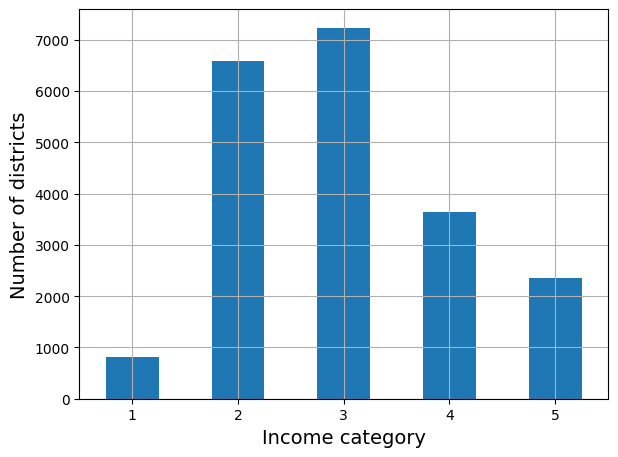

In [17]:
housing_with_id["income_cat"] = pd.cut(housing_with_id["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                               labels=[1, 2, 3, 4, 5])


housing_with_id["income_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")
save_fig("housing_with_id_income_cat_bar_plot")  # extra code
plt.show()

In [18]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)
strat_splits = []
for train_index, test_index in splitter.split(housing_with_id, housing_with_id["income_cat"]):
    strat_train_set_n = housing_with_id.iloc[train_index]
    strat_test_set_n = housing_with_id.iloc[test_index]
    strat_splits.append([strat_train_set_n, strat_test_set_n])

strat_train_set, strat_test_set = strat_splits[0]

In [19]:
strat_train_set, strat_test_set = train_test_split(
    housing_with_id, test_size=0.2, stratify=housing_with_id["income_cat"], random_state=42)

In [20]:
(strat_test_set["income_cat"].value_counts() / len(strat_test_set)).sort_index()

income_cat
1    0.039971
2    0.318798
3    0.350533
4    0.176357
5    0.114341
Name: count, dtype: float64

In [21]:
housing_with_id['income_cat'].value_counts() / len(housing_with_id)

income_cat
3    0.350581
2    0.318847
4    0.176308
5    0.114438
1    0.039826
Name: count, dtype: float64

In [22]:
housing_with_id.head()

,index,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,id,income_cat
0,0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,-122192.12,5
1,1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,-122182.14,5
2,2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,-122202.15,5
3,3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,-122212.15,4
4,4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,-122212.15,3


In [23]:
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "id")
# test  = housing.loc[test_set.index]
# test ["income_cat"].value_counts() / len(test_set)
(test_set['income_cat'].value_counts() / len(test_set)).sort_index()

income_cat
1    0.039833
2    0.321214
3    0.366142
4    0.171144
5    0.101667
Name: count, dtype: float64

In [24]:
def income_cat_proportions(data):
    return data["income_cat"].value_counts(normalize=True).sort_index()

overall = income_cat_proportions(housing_with_id)
stratified = income_cat_proportions(strat_test_set)
random = income_cat_proportions(test_set)
stratified_relative_error = (stratified / overall) -1
random_relative_error = (random / overall) - 1

bias_comparison = pd.DataFrame({
    "Overall %": 100 * overall,
    "Stratified %": 100 * stratified,
    "Random %": 100 * random,
    "Stratified Relative Error %": 100 * stratified_relative_error,
    "Random Relative Error %": 100 * random_relative_error,
    "Stratified Abs Error (points) %": 100 * (stratified - overall).abs(),
    "Random Abs Error (points) %": 100 * (random - overall).abs(),
})

bias_comparison.style.format({
    "Overall %": "{:.2f}",
    "Stratified %": "{:.2f}",
    "Random %": "{:.2f}",
    "Stratified Relative Error %": "{:.5f}",
    "Random Relative Error %": "{:.5f}",
    "Stratified Abs Error (points) %": "{:.5f}",
    "Random Abs Error (points) %": "{:.5f}",
})

,Overall %,Stratified %,Random %,Stratified Relative Error %,Random Relative Error %,Stratified Abs Error (points) %,Random Abs Error (points) %
income_cat,,,,,,,
1,3.98,4.00,3.98,0.36496,0.01927,0.01453,0.00077
2,31.88,31.88,32.12,-0.01520,0.74225,0.00484,0.23666
3,35.06,35.05,36.61,-0.01382,4.43844,0.00484,1.55603
4,17.63,17.64,17.11,0.02748,-2.92901,0.00484,0.51641
5,11.44,11.43,10.17,-0.08467,-11.15936,0.00969,1.27705


# Relative Error vs Absolute Error
Relative Error answers the question of how big that error is compared to the true value

Absolute Error answers the question of how far off the predicted value is from the actual value in units

In [25]:
error_summary = pd.DataFrame({
    "Mean Absolute Error (percentage points)": [
        100 * (stratified - overall).abs().mean(),
        100 * (random - overall).abs().mean(),
    ],
    "Maximum Absolute Error (percentage points)": [
        100 * (stratified - overall).abs().max(),
        100 * (random - overall).abs().max(),
    ],
}, index=["Stratified", "Random"])

error_summary.style.format({
    "Mean Absolute Error (percentage points)": "{:.5f}",
    "Maximum Absolute Error (percentage points)": "{:.5f}",
})

,Mean Absolute Error (percentage points),Maximum Absolute Error (percentage points)
Stratified,0.00775,0.01453
Random,0.71739,1.55603


In [26]:
housing = housing_with_id.drop(columns=["index", "income_cat", "id"])

In [27]:
for dataset in (strat_train_set, strat_test_set, train_set, test_set):
    dataset.drop(
        columns=["id", "index", "income_cat"],
        errors="ignore",
        inplace=True,
    )

C:\Users\DanieHKombe\AppData\Local\Temp\ipykernel_17700\174803561.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset.drop(
C:\Users\DanieHKombe\AppData\Local\Temp\ipykernel_17700\174803561.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset.drop(


In [28]:
housing_vis = strat_train_set.copy()

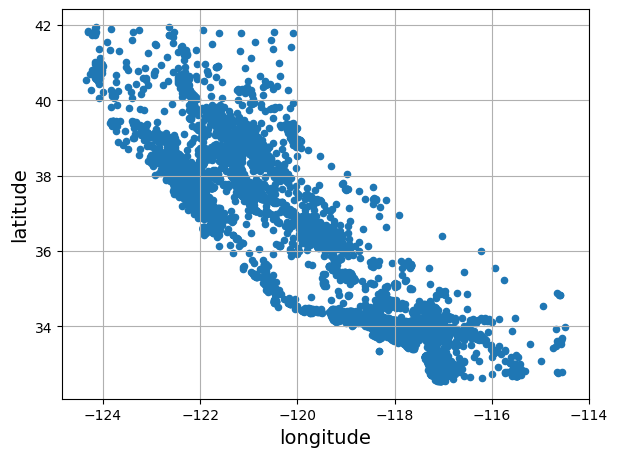

In [29]:
housing_vis.plot(kind="scatter", x="longitude", y="latitude", grid=True)
save_fig("bad_visualization_plot")  # extra code
plt.show()

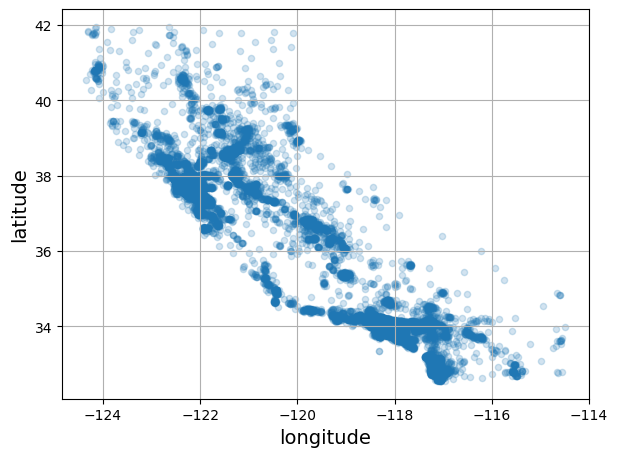

In [30]:
housing_vis.plot(kind="scatter", x="longitude", y="latitude", grid=True, alpha=0.2)
save_fig("better_visualization_plot")  # extra code
plt.show()

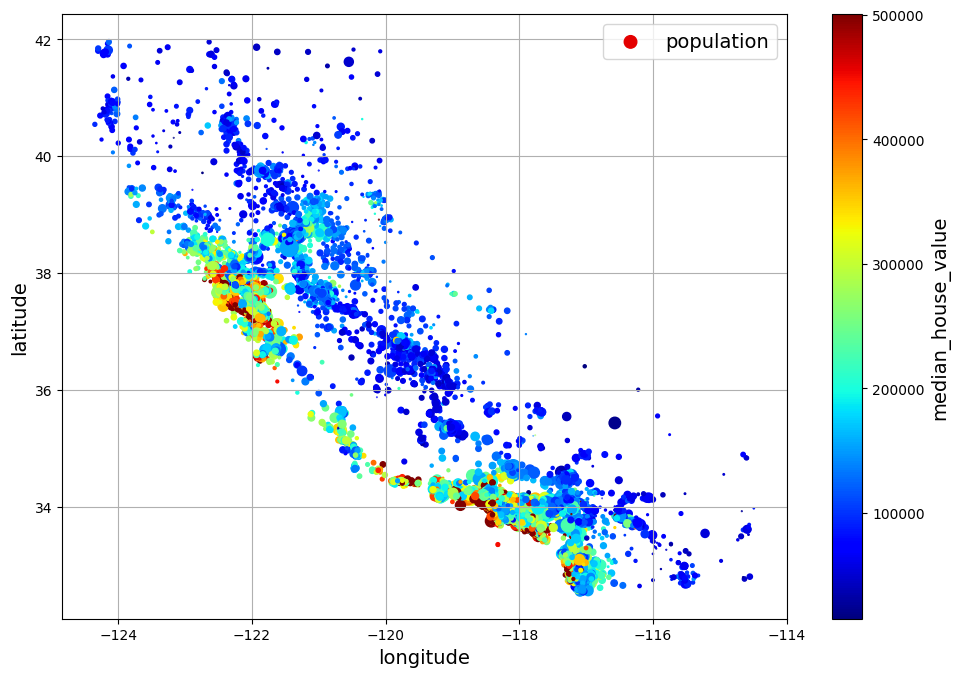

In [31]:
housing_vis.plot(kind="scatter", x="longitude", y="latitude", grid=True,
             s=housing_vis["population"] / 100, label="population",
             c="median_house_value", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))
save_fig("housing_prices_scatterplot")  # extra code
plt.show()

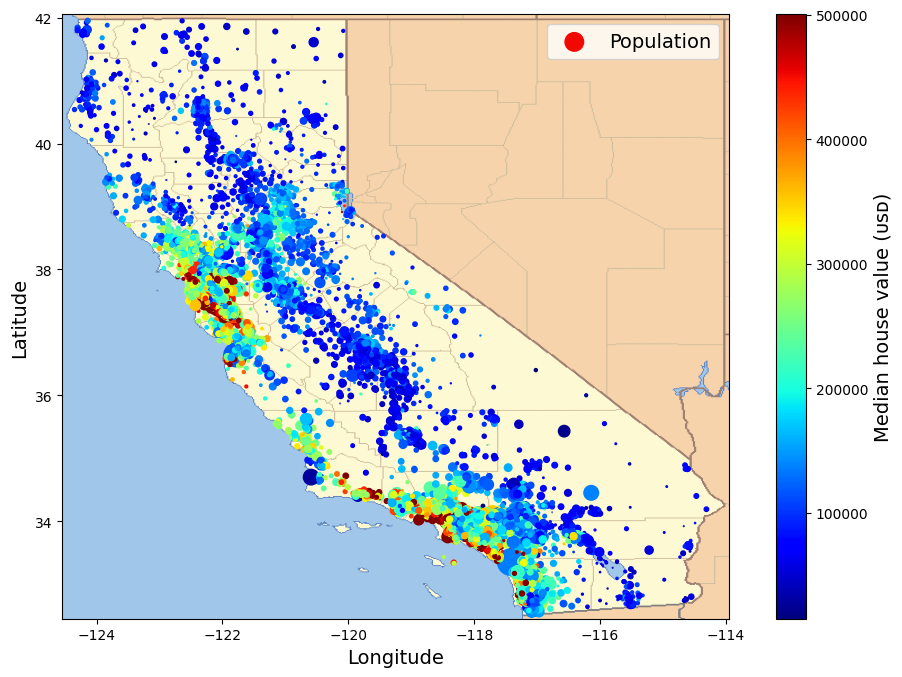

In [32]:
# Download the California image
filename = "california.png"
if not (IMAGES_PATH / filename).is_file():
    homl3_root = "https://github.com/ageron/handson-ml3/raw/main/"
    url = homl3_root + "images/end_to_end_project/" + filename
    print("Downloading", filename)
    urllib.request.urlretrieve(url, IMAGES_PATH / filename)

housing_renamed = housing.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed.plot(
             kind="scatter", x="Longitude", y="Latitude",
             s=housing_renamed["Population"] / 100, label="Population",
             c="Median house value (ᴜsᴅ)", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))

california_img = plt.imread(IMAGES_PATH / filename)
axis = -124.55, -113.95, 32.45, 42.05
plt.axis(axis)
plt.imshow(california_img, extent=axis)

save_fig("california_housing_prices_plot")
plt.show()

In [33]:
corr_matrix = housing_vis.corr(numeric_only=True)
corr_matrix[target].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

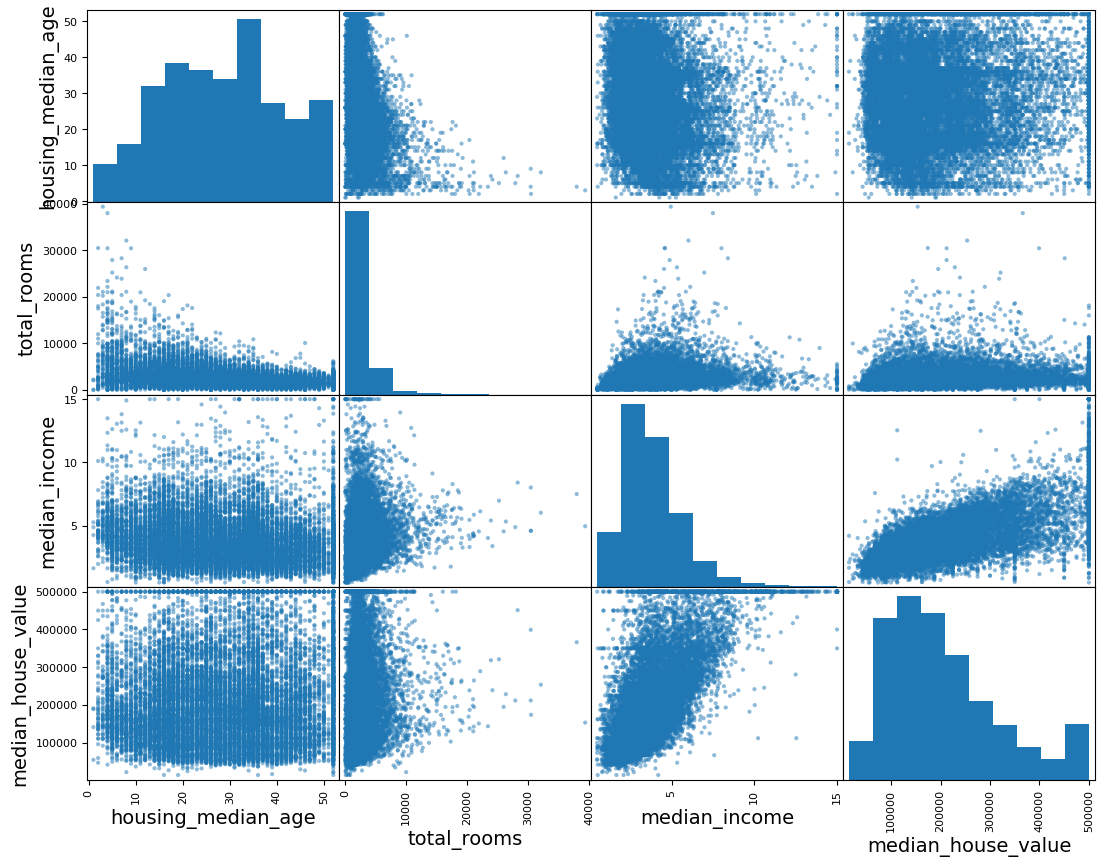

In [34]:
from pandas.plotting import scatter_matrix

attributes = corr_matrix[corr_matrix[target] > 0.1].index.tolist()
# attributes
scatter_matrix(housing_vis[attributes], figsize=(13, 10))
plt.show()

In [35]:
housing_vis["rooms_per_house"] = housing_vis["total_rooms"] / housing_vis["households"]
housing_vis["bedrooms_ratio"] = housing_vis["total_bedrooms"] / housing_vis["total_rooms"]
housing_vis["people_per_house"] = housing_vis["population"] / housing_vis["households"]

In [36]:
corr_matrix = housing_vis.corr(numeric_only=True)
corr_matrix[target].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
rooms_per_house       0.143663
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
people_per_house     -0.038224
longitude            -0.050859
latitude             -0.139584
bedrooms_ratio       -0.256397
Name: median_house_value, dtype: float64

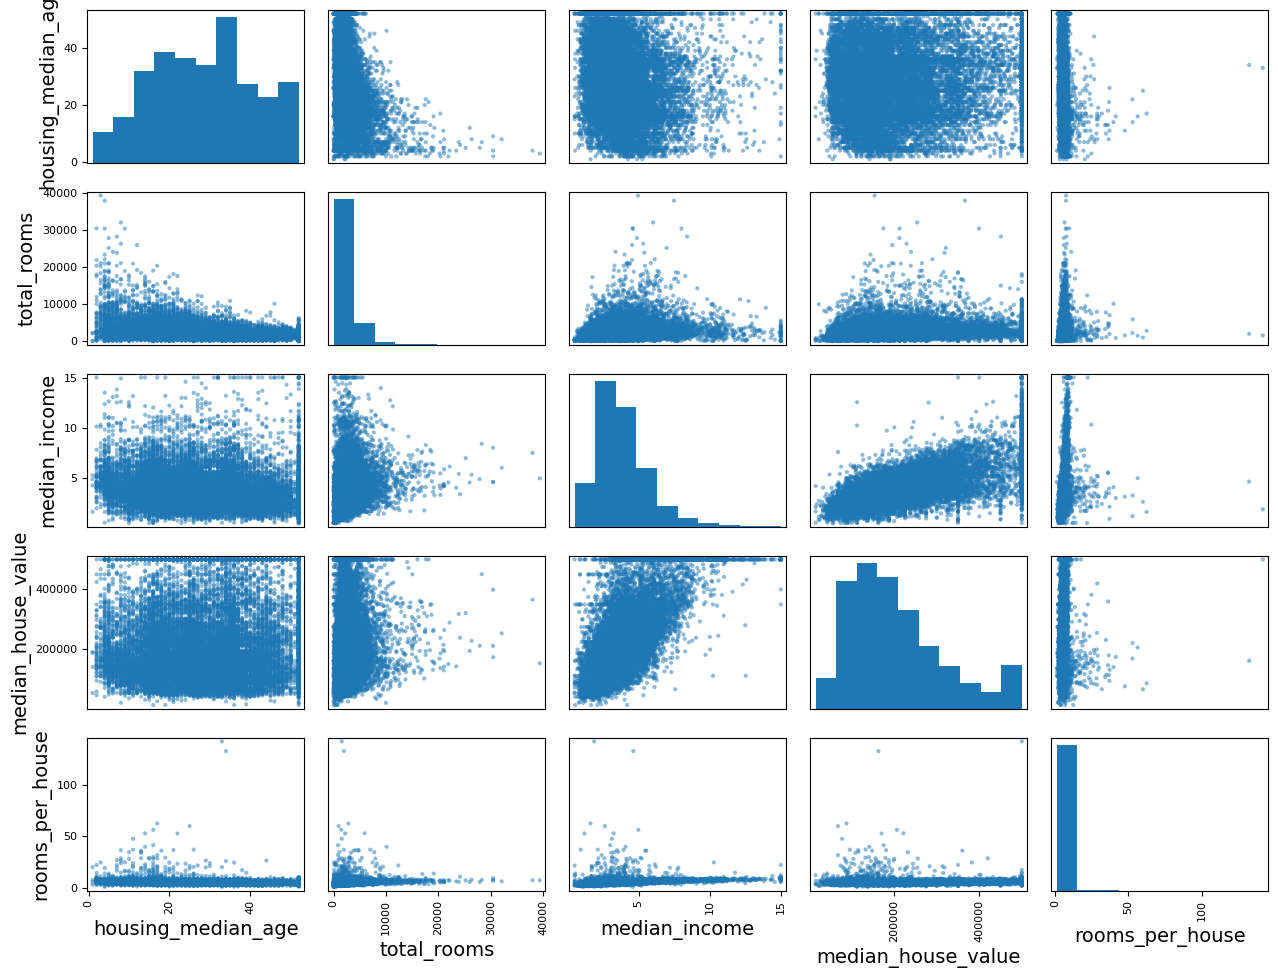

In [37]:
from pandas.plotting import scatter_matrix

attributes = corr_matrix[corr_matrix[target] > 0.1].index.tolist()
# attributes
scatter_matrix(housing_vis[attributes], figsize=(13, 10))
save_fig("corr_scatter_matrix_plot")
plt.show()

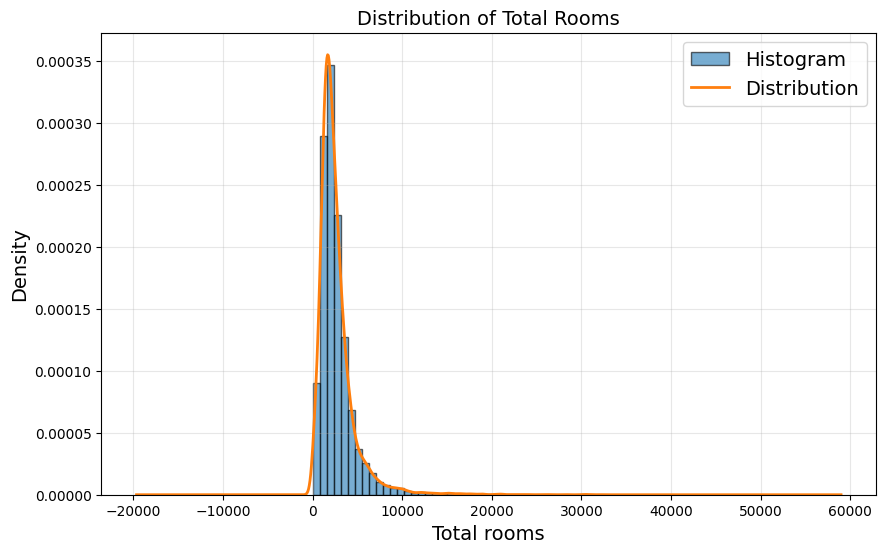

In [38]:
rooms = housing_vis["total_rooms"].dropna()

fig, ax = plt.subplots(figsize=(10, 6))

rooms.plot(
    kind="hist",
    bins=50,
    density=True,
    alpha=0.6,
    edgecolor="black",
    ax=ax,
    label="Histogram"
)

rooms.plot(
    kind="density",
    linewidth=2,
    ax=ax,
    label="Distribution"
)

ax.set_xlabel("Total rooms")
ax.set_ylabel("Density")
ax.set_title("Distribution of Total Rooms")
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()

In [39]:
housing_pre = strat_train_set.drop(target, axis=1)
housing_labels = strat_train_set[target].copy()

In [40]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

In [41]:
housing_numerical = housing_pre.select_dtypes(include=[np.number])

In [42]:
imputer.fit(housing_numerical)

,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False


The imputer has simply computed the median of each attribute and stored the results in statistics_ instance variable. Only one attribute, total_rooms, had NAN, but you cannot be sure the there won't be any more missing values in new data after the system goes live

In [43]:
print(imputer.statistics_)
print("\n")
housing_numerical.median().values

[-118.51     34.26     29.     2125.      434.     1167.      408.
    3.5385]




array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [44]:
X = imputer.transform(housing_numerical)

housing_tr = pd.DataFrame(X, columns=housing_numerical.columns, index=housing_numerical.index)

In [45]:
null_rows_idx = housing.isnull().any(axis=1)
housing_tr.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
14452,-120.67,40.50,15.0,5343.0,434.0,2503.0,902.0,3.5962
18217,-117.96,34.03,35.0,2093.0,434.0,1755.0,403.0,3.4115
11889,-118.05,34.04,33.0,1348.0,434.0,1098.0,257.0,4.2917
20325,-118.88,34.17,15.0,4260.0,434.0,1701.0,669.0,5.1033
14360,-117.87,33.62,8.0,1266.0,434.0,375.0,183.0,9.8020


In [46]:
housing_cat = strat_train_set[["ocean_proximity"]]
housing_cat.head(10)

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY
18031,<1H OCEAN
6753,<1H OCEAN


In [47]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_enc = OrdinalEncoder()
housing_cat_enc = ordinal_enc.fit_transform(housing_cat)

housing_cat_enc[:10]

array([[3.],
       [0.],
       [1.],
       [1.],
       [4.],
       [1.],
       [0.],
       [3.],
       [0.],
       [0.]])

In [48]:
ordinal_enc.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

For a feature like ocean_proximity, these categories are nominal, not naturally ordered. There is no meaningful numerical progression between them.

In [49]:
from sklearn.preprocessing import OneHotEncoder

cat_enc = OneHotEncoder()
housing_cat_1hot = cat_enc.fit_transform(housing_cat)

In [50]:
housing_cat_1hot

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16512 stored elements and shape (16512, 5)>

## Encoding Categorical Data

Ordinal encoding assigns numbers to categories, which can create a false sense of order. For example, `INLAND = 0` and `ISLAND = 3` may incorrectly suggest that one category is greater than the other.



One-hot encoding creates a separate 0/1 column for each category. This avoids artificial order and is usually better for nominal data such as `ocean_proximity`.



Use ordinal encoding when categories have a real order, such as `poor`, `average`, and `excellent`. Use one-hot encoding when categories are simply different.

In [51]:
housing_cat_1hot.toarray()[:10]

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0.]])

In [52]:
cat_enc.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [53]:
cat_enc.feature_names_in_

array(['ocean_proximity'], dtype=object)

In [54]:
cat_enc.get_feature_names_out()

array(['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'], dtype=object)

# Feature Scaling


In [55]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler(feature_range=(-1, 1)) # NN works best with a zero-mean inputs
housing_num_mm_scaled = min_max_scaler.fit_transform(housing_numerical)

In [56]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
housing_num_std_scaled = std_scaler.fit_transform(housing_numerical)

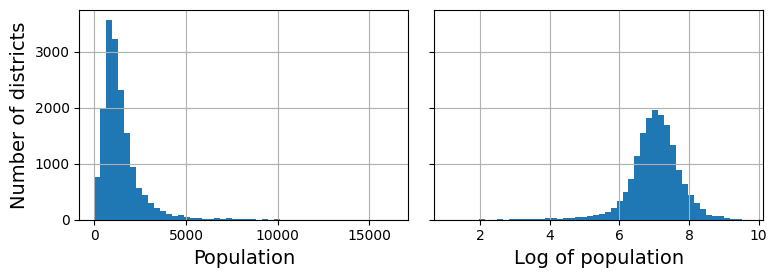

In [57]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
housing_pre["population"].hist(ax=axs[0], bins=50)
housing_pre["population"].apply(np.log).hist(ax=axs[1], bins=50)
axs[0].set_xlabel("Population")
axs[1].set_xlabel("Log of population")
axs[0].set_ylabel("Number of districts")
save_fig("long_tail_plot")
plt.show()

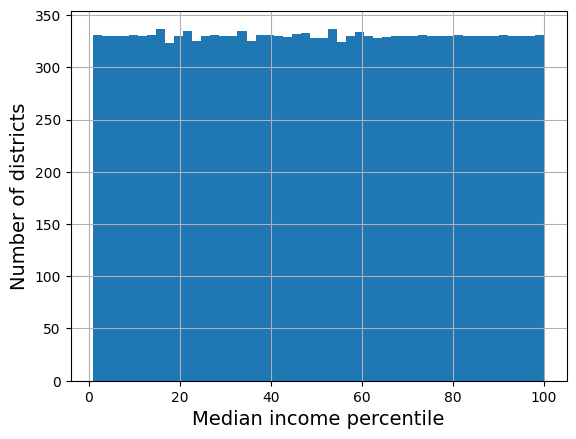

In [58]:
# Uniform distribution of median income by flattening the long tail of the distribution
percentiles = [np.percentile(housing_pre["median_income"], p)
               for p in range(1, 100)]
flattened_median_income = pd.cut(housing_pre["median_income"],
                                 bins=[-np.inf] + percentiles + [np.inf],
                                 labels=range(1, 100 + 1))
flattened_median_income.hist(bins=50)
plt.xlabel("Median income percentile")
plt.ylabel("Number of districts")
plt.show()
# Note: incomes below the 1st percentile are labeled 1, and incomes above the
# 99th percentile are labeled 100. This is why the distribution below ranges
# from 1 to 100 (not 0 to 100).

In [59]:
from sklearn.metrics.pairwise import rbf_kernel

age_simil_35 = rbf_kernel(housing_pre[["housing_median_age"]], [[35]], gamma=0.1)

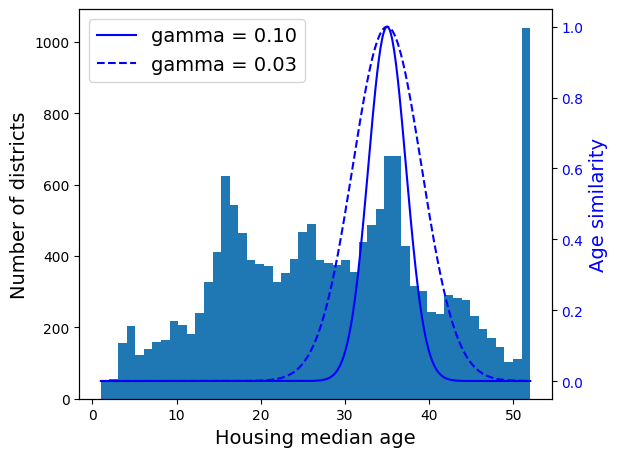

In [60]:
ages = np.linspace(housing_pre["housing_median_age"].min(),
                   housing_pre["housing_median_age"].max(),
                   500).reshape(-1, 1)
gamma1 = 0.1
gamma2 = 0.03
rbf1 = rbf_kernel(ages, [[35]], gamma=gamma1)
rbf2 = rbf_kernel(ages, [[35]], gamma=gamma2)

fig, ax1 = plt.subplots()

ax1.set_xlabel("Housing median age")
ax1.set_ylabel("Number of districts")
ax1.hist(housing_pre["housing_median_age"], bins=50)

ax2 = ax1.twinx()  # create a twin axis that shares the same x-axis
color = "blue"
ax2.plot(ages, rbf1, color=color, label="gamma = 0.10")
ax2.plot(ages, rbf2, color=color, label="gamma = 0.03", linestyle="--")
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylabel("Age similarity", color=color)

plt.legend(loc="upper left")
save_fig("age_similarity_plot")
plt.show()

In [61]:
from sklearn.linear_model import LinearRegression

target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())

model = LinearRegression()
model.fit(housing_pre[["median_income"]], scaled_labels)
some_new_data = housing_pre[["median_income"]].iloc[:5] 
# this iloc selects the first 5 rows of the median_income column from the 
# housing DataFrame. It is used to demonstrate how to make predictions using 
# the trained linear regression model. Pretend that these are new data 
# points for which we want to predict the scaled median house values.

scaled_predictions = model.predict(some_new_data)
predictions = target_scaler.inverse_transform(scaled_predictions)

# Old way to make predictions (before scaling the target variable)

In [62]:
predictions

array([[131997.15275877],
       [299359.35844434],
       [146023.37185694],
       [138840.33653057],
       [192016.61557639]])

In [63]:
from sklearn.compose import TransformedTargetRegressor

model = TransformedTargetRegressor(regressor=LinearRegression(),
                                   transformer=StandardScaler())
model.fit(housing_pre[["median_income"]], housing_labels)
predictions = model.predict(some_new_data)

In [64]:
predictions

array([131997.15275877, 299359.35844434, 146023.37185694, 138840.33653057,
       192016.61557639])

# Custom Transformer

In [65]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_pop = log_transformer.transform(housing_pre[["population"]])

In [66]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class StandardScalerWithInverse(BaseEstimator, TransformerMixin):
    def __init__(self, with_mean=True): #no *args or **kwargs
        self.with_mean = with_mean

    def fit(self, X, y=None):  # y is required even though we don't use it
        X = check_array(X)  # checks that X is an array with finite float values
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.n_features_in_ = X.shape[1]  # every estimator stores this in fit()
        return self  # always return self!

    def transform(self, X):
        check_is_fitted(self)  # looks for learned attributes (with trailing _)
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]
        if self.with_mean:
            X = X - self.mean_
        return X / self.scale_

    def inverse_transform(self, X):
        check_is_fitted(self)
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]
        return X * self.scale_ + self.mean_

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self)
        if input_features is None:
            input_features = [f"x{i}" for i in range(self.n_features_in_)]
        else:
            assert len(input_features) == self.n_features_in_
        return np.array(input_features, dtype=object)



In [67]:
from sklearn.cluster import KMeans

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, n_init=10,
                              random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self  # always return self!

    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)
    
    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

In [68]:
cluster_sim = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)

similarities = cluster_sim.fit_transform(housing_pre[["latitude", "longitude"]],
                                         sample_weight=housing_labels)

In [69]:
similarities[:3].round(2)

array([[0.08, 0.  , 0.6 , 0.  , 0.  , 0.99, 0.  , 0.  , 0.  , 0.14],
       [0.  , 0.99, 0.  , 0.04, 0.  , 0.  , 0.11, 0.  , 0.63, 0.  ],
       [0.44, 0.  , 0.3 , 0.  , 0.  , 0.7 , 0.  , 0.01, 0.  , 0.29]])

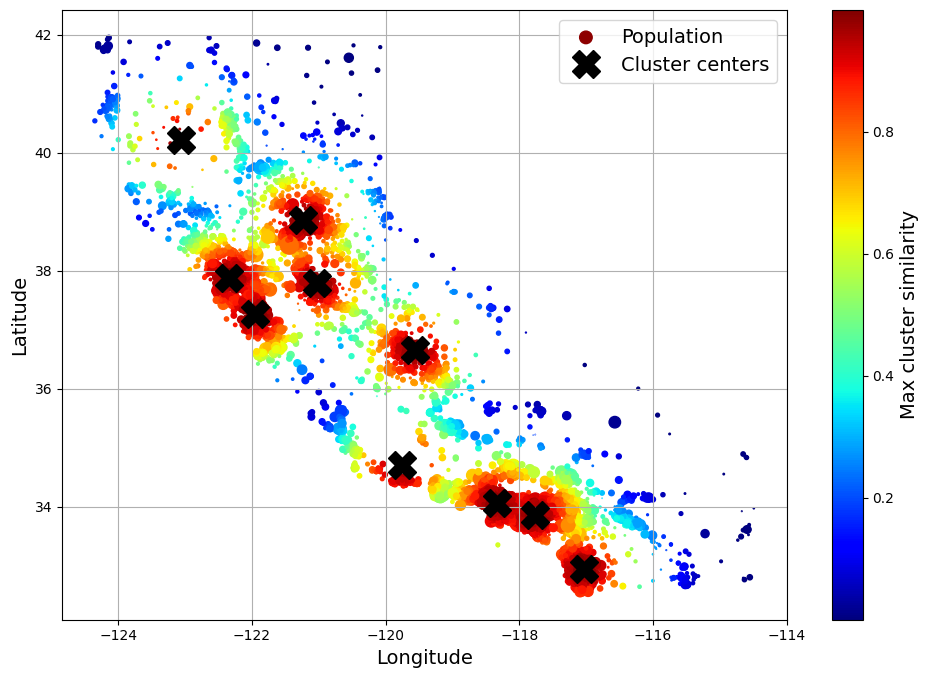

In [70]:
housing_renamed = housing_pre.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed["Max cluster similarity"] = similarities.max(axis=1)

housing_renamed.plot(kind="scatter", x="Longitude", y="Latitude", grid=True,
                     s=housing_renamed["Population"] / 100, label="Population",
                     c="Max cluster similarity",
                     cmap="jet", colorbar=True,
                     legend=True, sharex=False, figsize=(10, 7))
plt.plot(cluster_sim.kmeans_.cluster_centers_[:, 1],
         cluster_sim.kmeans_.cluster_centers_[:, 0],
         linestyle="", color="black", marker="X", markersize=20,
         label="Cluster centers")
plt.legend(loc="upper right")
save_fig("district_cluster_plot")
plt.show()

# Transformation Pipelines
Numerical Attributes

In [71]:
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("standardize", StandardScaler())
])

In [72]:
housing_num_prep = numeric_pipeline.fit_transform(housing_numerical)
housing_num_prep[:2].round(2)

array([[-1.42,  1.01,  1.86,  0.31,  1.37,  0.14,  1.39, -0.94],
       [ 0.6 , -0.7 ,  0.91, -0.31, -0.44, -0.69, -0.37,  1.17]])

In [73]:
df_housing_num_prep = pd.DataFrame(
    housing_num_prep, columns=numeric_pipeline.get_feature_names_out(),
    index=housing_numerical.index
)

df_housing_num_prep.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942
3785,-1.203098,1.276119,0.351428,-0.712240,-0.760709,-0.788768,-0.775727,-0.759789
14689,1.231216,-0.884924,-0.919891,0.702262,0.742306,0.383175,0.731375,-0.850281
20507,0.711362,-0.875549,0.589800,0.790125,1.595753,0.444376,1.755263,-0.180365


In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

numeric_attribs = housing_numerical.columns.to_list()
cat_attribs = ["ocean_proximity"]

cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)

preprocessing = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_attribs),
    ("cat", cat_pipeline, cat_attribs),
])

In [75]:
from sklearn.compose import make_column_selector, make_column_transformer

preprocessing = make_column_transformer(
    (numeric_pipeline, make_column_selector(dtype_include=np.number)),
    (cat_pipeline, make_column_selector(dtype_include=object)),
)

In [76]:
housing_prepared = preprocessing.fit_transform(housing_pre)

In [77]:
housing_prepared_df = pd.DataFrame(
    housing_prepared,
    columns=preprocessing.get_feature_names_out(),
    index=housing_pre.index
)
housing_prepared_df.head()

,pipeline-1__longitude,pipeline-1__latitude,pipeline-1__housing_median_age,pipeline-1__total_rooms,pipeline-1__total_bedrooms,pipeline-1__population,pipeline-1__households,pipeline-1__median_income,pipeline-2__ocean_proximity_<1H OCEAN,pipeline-2__ocean_proximity_INLAND,pipeline-2__ocean_proximity_ISLAND,pipeline-2__ocean_proximity_NEAR BAY,pipeline-2__ocean_proximity_NEAR OCEAN
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491,0.0,0.0,0.0,1.0,0.0
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942,1.0,0.0,0.0,0.0,0.0
3785,-1.203098,1.276119,0.351428,-0.712240,-0.760709,-0.788768,-0.775727,-0.759789,0.0,1.0,0.0,0.0,0.0
14689,1.231216,-0.884924,-0.919891,0.702262,0.742306,0.383175,0.731375,-0.850281,0.0,1.0,0.0,0.0,0.0
20507,0.711362,-0.875549,0.589800,0.790125,1.595753,0.444376,1.755263,-0.180365,0.0,0.0,0.0,0.0,1.0


In [78]:
def column_ratio(X):
    ### Calculate the ratio of the first column to the second column
    ### Input: X - a 2D numpy array
    ### Output: a 2D numpy array with the ratio of the first column to the second column
    return X[:, [0]] / X[:, [1]] 

def ratio_name(function_transformer, feature_names_in):
    # Return the names of the features after the transformation
    return["ratio"] # Feature names out must be a list of strings, so we return a list with a single string "ratio"

def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(column_ratio, feature_names_out=ratio_name),
        StandardScaler()
    )

log_pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(np.log, feature_names_out="one-to-one"),
        StandardScaler()
    )
cluster_sim = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
default_num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

preprocessing = ColumnTransformer([
        ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
        ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
        ("people_per_house", ratio_pipeline(), ["population", "households"]),
        ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population",
                               "households", "median_income"]),
        ("geo", cluster_sim, ["latitude", "longitude"]),
        ("cat", cat_pipeline, make_column_selector(dtype_include=object)),
    ],
    remainder=default_num_pipeline)  # one column remaining: housing_median_age


In [79]:
# Scaling the target
target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())

In [80]:
housing_prepared = preprocessing.fit_transform(housing_pre)
housing_prepared.shape

(16512, 24)

In [81]:
preprocessing.get_feature_names_out()

array(['bedrooms__ratio', 'rooms_per_house__ratio',
       'people_per_house__ratio', 'log__total_bedrooms',
       'log__total_rooms', 'log__population', 'log__households',
       'log__median_income', 'geo__Cluster 0 similarity',
       'geo__Cluster 1 similarity', 'geo__Cluster 2 similarity',
       'geo__Cluster 3 similarity', 'geo__Cluster 4 similarity',
       'geo__Cluster 5 similarity', 'geo__Cluster 6 similarity',
       'geo__Cluster 7 similarity', 'geo__Cluster 8 similarity',
       'geo__Cluster 9 similarity', 'cat__ocean_proximity_<1H OCEAN',
       'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND',
       'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN',
       'remainder__housing_median_age'], dtype=object)

In [ ]:
# from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(
    preprocessing,
    LinearRegression()
)
lin_reg.fit(housing_pre, scaled_labels.ravel())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bedrooms', ...), ('rooms_per_house', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",Pipeline(step...ardScaler())])
,"sparse_threshold sparse_threshold: float

In [83]:
housing_pre.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,NEAR BAY
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,<1H OCEAN
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,INLAND
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,INLAND
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,NEAR OCEAN


In [ ]:
scaled_predictions = lin_reg.predict(housing_pre)
housing_predictions = target_scaler.inverse_transform(
    scaled_predictions.reshape(-1,1)
).ravel()
housing_predictions[:5].round(-2)  # -2 = rounded to the nearest hundred

array([242800., 375900., 127500.,  99400., 324600.])

In [85]:
housing_labels.iloc[:5].values

array([458300., 483800., 101700.,  96100., 361800.])

In [86]:
error_ratios = housing_predictions[:5].round(-2) / housing_labels.iloc[:5].values - 1
print(", ".join([f"{100 * ratio:.1f}%" for ratio in error_ratios]))

-47.0%, -22.3%, 25.4%, 3.4%, -10.3%


In [87]:
from sklearn.metrics import root_mean_squared_error
# try:
#     from sklearn.metrics import root_mean_squared_error
# except ImportError:
#     from sklearn.metrics import mean_squared_error

#     def root_mean_squared_error(labels, predictions):
#         return mean_squared_error(labels, predictions, squared=False)

lin_rmse = root_mean_squared_error(housing_labels, housing_predictions)
lin_rmse

68647.95686706626

In [ ]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = make_pipeline(
    preprocessing,
    DecisionTreeRegressor(random_state=42)
)
tree_reg.fit(housing_pre, housing_labels)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('decisiontreeregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bedrooms', ...), ('rooms_per_house', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",Pipeline(step...ardScaler())])
,"sparse_threshold sparse_threshol

In [ ]:
housing_predictions = tree_reg.predict(housing_pre)
tree_rmse = root_mean_squared_error(housing_labels, housing_predictions)
tree_rmse

0.0

# Cross-Validation

In [ ]:
from sklearn.model_selection import cross_val_score

tree_rmses = -cross_val_score(tree_reg, housing_pre, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=10)

In [91]:
pd.Series(tree_rmses).describe()

count       10.000000
mean     67153.318273
std       1963.580924
min      63925.253106
25%      66083.277180
50%      66795.829871
75%      68074.018403
max      70664.635833
dtype: float64

In [ ]:
lin_rmses = -cross_val_score(
    lin_reg,
    housing_pre,
    housing_labels,
    scoring="neg_root_mean_squared_error",
    cv=10,
)
pd.Series(lin_rmses).describe()

count       10.000000
mean     69847.923224
std       4078.407329
min      65659.761079
25%      68088.799156
50%      68697.591463
75%      69800.966364
max      80685.254832
dtype: float64

In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = make_pipeline(
    preprocessing,
    RandomForestRegressor(random_state=42)
)
forest_rmses = -cross_val_score(
    forest_reg,
    housing_pre,
    housing_labels,
    scoring="neg_root_mean_squared_error", cv=10
)

In [94]:
pd.Series(forest_rmses).describe()

count       10.000000
mean     47002.931706
std       1048.451340
min      45667.064036
25%      46494.358345
50%      47093.173938
75%      47274.873814
max      49354.705514
dtype: float64

In [ ]:
forest_reg.fit(housing_pre, scaled_labels.ravel())
scaled_predictions = forest_reg.predict(housing_pre)
housing_predictions = target_scaler.inverse_transform(
    scaled_predictions.reshape(-1, 1)
).ravel()
forest_rmse = root_mean_squared_error(housing_labels, housing_predictions)
forest_rmse

17586.232749995146

The training error is much lower than the validation error, which usually means that the model has overfit the training set.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

svr_pipeline = make_pipeline(
    preprocessing,
    SVR(kernel="rbf")
)

param_grid = {
    "svr__C": [0.1, 1, 10, 100],
    "svr__gamma": ["scale", 0.01, 0.1, 1],
    "svr__epsilon": [0.01, 0.1, 0.2],
}

grid_search = GridSearchCV(
    svr_pipeline,
    param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(housing_pre, scaled_labels.ravel())
grid_search_model = grid_search

# grid_search_model.best_params_
# grid_search_model.best_score_
# grid_search_model.best_estimator_

In [97]:
# print(grid_search_model.best_params_)
# print(grid_search_model.best_score_)
print(grid_search_model.best_estimator_)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x000...
                                                   'median_income']),
                                                 ('geo',
                    

In [106]:
pd.Series(grid_search_model.best_score_).describe()

count    1.000000
mean    -0.458299
std           NaN
min     -0.458299
25%     -0.458299
50%     -0.458299
75%     -0.458299
max     -0.458299
dtype: float64

In [ ]:
svm_reg = make_pipeline(
    preprocessing,
    SVR(kernel='rbf', C=10, epsilon=0.2, gamma=0.1)
)

svm_rmses = -cross_val_score(
    svm_reg,
    housing_pre,
    scaled_labels.ravel(),
    scoring="neg_root_mean_squared_error", cv=10
)

In [100]:
pd.Series(svm_rmses).describe()

count    10.000000
mean      0.453017
std       0.013851
min       0.427137
25%       0.447009
50%       0.454655
75%       0.457943
max       0.476831
dtype: float64

In [101]:
target_scaler.scale_

array([115310.55565038])

In [102]:
cv_rmse_dollars = svm_rmses * target_scaler.scale_[0]
print(cv_rmse_dollars.mean())
print(cv_rmse_dollars.std())

52237.68592889076
1515.1660334094654


In [103]:
svm_reg.fit(housing_pre, scaled_labels.ravel())
svm_scaled_predictions = svm_reg.predict(housing_pre)
svm_housing_predictions = target_scaler.inverse_transform(
    svm_scaled_predictions.reshape(-1, 1)
).ravel()

svm_rmse = root_mean_squared_error(housing_labels, svm_housing_predictions)
svm_rmse

45411.57990029439

In [ ]:
from sklearn.model_selection import GridSearchCV

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestRegressor(random_state=42)),
])

param_grid = [
    {'preprocessing__geo__n_clusters': [5, 8, 10],
     'random_forest__max_features': [4, 6, 8]},
    {'preprocessing__geo__n_clusters': [10, 15],
     'random_forest__max_features': [6, 8, 10]},
]
grid_search = GridSearchCV(forest_reg, param_grid, cv=3,
                           scoring='neg_root_mean_squared_error')
grid_search.fit(housing_pre, housing_labels)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'preprocessing__geo__n_clusters': [5, 8, ...], 'random_forest__max_features': [4, 6, ...]}, {'preprocessing__geo__n_clusters': [10, 15], 'random_forest__max_features': [6, 8, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity

In [108]:
print(str(full_pipeline.get_params().keys())[:1000] + "...")

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'preprocessing', 'random_forest', 'preprocessing__force_int_remainder_cols', 'preprocessing__n_jobs', 'preprocessing__remainder__memory', 'preprocessing__remainder__steps', 'preprocessing__remainder__transform_input', 'preprocessing__remainder__verbose', 'preprocessing__remainder__simpleimputer', 'preprocessing__remainder__standardscaler', 'preprocessing__remainder__simpleimputer__add_indicator', 'preprocessing__remainder__simpleimputer__copy', 'preprocessing__remainder__simpleimputer__fill_value', 'preprocessing__remainder__simpleimputer__keep_empty_features', 'preprocessing__remainder__simpleimputer__missing_values', 'preprocessing__remainder__simpleimputer__strategy', 'preprocessing__remainder__standardscaler__copy', 'preprocessing__remainder__standardscaler__with_mean', 'preprocessing__remainder__standardscaler__with_std', 'preprocessing__remainder', 'preprocessing__sparse_threshold', 'preprocessing__transformer_weights', 

In [109]:
grid_search.best_params_

{'preprocessing__geo__n_clusters': 15, 'random_forest__max_features': 6}

In [110]:
grid_search.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bedrooms', ...), ('rooms_per_house', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",Pipeline(step...ardScaler())])
,"sparse_threshold sparse_threshold: float, de

In [111]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)

# These few lines of code just make the DataFrame look nicer
cv_res = cv_res[["param_preprocessing__geo__n_clusters",
                 "param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
score_cols = ["split0", "split1", "split2", "mean_test_rmse"]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)

cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
12,15,6,43536,43753,44569,43953
13,15,8,44084,44205,44863,44384
14,15,10,44368,44496,45200,44688
7,10,6,44251,44628,45857,44912
9,10,6,44251,44628,45857,44912


## Save data and fitted models
Run these added cells after the existing modeling cells. All original code is preserved. The tuned random forest is retrained using the final grid search settings.


In [ ]:
from pathlib import Path
import json
import platform
import cloudpickle
import sklearn
from sklearn.base import clone

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "notebooks" / "notebook.ipynb").is_file())
MODELS_PATH = PROJECT_ROOT / "models" / "saved_work"
MODELS_PATH.mkdir(parents=True, exist_ok=True)

# GridSearchCV refits automatically; explicitly retrain a separate final model.
# Use the current search result when available; otherwise the recorded best params.
best_forest_params = {"preprocessing__geo__n_clusters": 15,
                      "random_forest__max_features": 6}
if "grid_search" in globals() and "random_forest__max_features" in grid_search.best_params_:
    best_forest_params = dict(grid_search.best_params_)
final_forest_reg = clone(full_pipeline).set_params(**best_forest_params)
final_forest_reg.fit(housing_pre, housing_labels)

# Keep both the original 10-cluster features and the tuned model's 15-cluster features.
saved_preprocessing = clone(preprocessing).fit(housing_pre)
housing_prepared = saved_preprocessing.transform(housing_pre)
housing_prepared_df = pd.DataFrame(housing_prepared,
    columns=saved_preprocessing.get_feature_names_out(), index=housing_pre.index)
housing_test = strat_test_set.drop(columns=[target]).copy()
housing_test_labels = strat_test_set[target].copy()
housing_test_prepared = saved_preprocessing.transform(housing_test)
final_preprocessing = final_forest_reg.named_steps["preprocessing"]
housing_prepared_tuned = final_preprocessing.transform(housing_pre)
housing_test_prepared_tuned = final_preprocessing.transform(housing_test)

dataset = dict(target=target, housing_pre=housing_pre, housing_labels=housing_labels,
    scaled_labels=scaled_labels, housing_prepared=housing_prepared,
    housing_prepared_df=housing_prepared_df, strat_train_set=strat_train_set,
    strat_test_set=strat_test_set, housing_test=housing_test,
    housing_test_labels=housing_test_labels, housing_test_prepared=housing_test_prepared,
    housing_prepared_tuned=housing_prepared_tuned,
    housing_test_prepared_tuned=housing_test_prepared_tuned,
    tuned_feature_names=final_preprocessing.get_feature_names_out())
models = dict(lin_reg=lin_reg, tree_reg=tree_reg, forest_reg=forest_reg,
              svm_reg=svm_reg, final_forest_reg=final_forest_reg)
# Cloudpickle includes notebook-defined transformers and functions for fresh kernels.
def save_artifact(name, value):
    with (MODELS_PATH / name).open("wb") as stream:
        cloudpickle.dump(value, stream)

# Original line: save_artifact("/dataset.pkl", dataset)
save_artifact("dataset.pkl", dataset)
save_artifact("preprocessing.pkl", saved_preprocessing)
save_artifact("target_scaler.pkl", target_scaler)
# Original incomplete call retained: save_artifact("")
for name, estimator in models.items():
    save_artifact(f"{name}.pkl", estimator)
manifest = dict(python=platform.python_version(), sklearn=sklearn.__version__,
    numpy=np.__version__, pandas=pd.__version__, cloudpickle=cloudpickle.__version__,
    best_forest_params=best_forest_params,
    prediction_targets={"lin_reg": "scaled", "tree_reg": "dollars",
        "forest_reg": "scaled", "svm_reg": "scaled", "final_forest_reg": "dollars"})
(MODELS_PATH / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(MODELS_PATH / "requirements.txt").write_text(
    "\n".join(f"{name}=={version}" for name, version in {
        "scikit-learn": sklearn.__version__, "numpy": np.__version__,
        "pandas": pd.__version__, "cloudpickle": cloudpickle.__version__,
        # Original invalid package-version entry: "Linear_Regression":LinearRegression.__version__,
        # Original invalid package-version entry: "Decision_Tree_Regressor":DecisionTreeRegressor.__version__,
        # Original invalid package-version entry: "Random_Forest_Regressor":RandomForestRegressor.__version__,
        # Original invalid package-version entry: "Support_Vector_Machine":SVR.__version__,}.items()) + "\n",
    }.items()) + "\n",
    encoding="utf-8")
print(f"Saved training/test data, preprocessing, target scaler and {len(models)} models to {MODELS_PATH}")


Saved training/test data, preprocessing, target scaler and 5 models to c:\Datasets\House\models\saved_work
